In [2]:
# need to take averages of fluxes over all dumps, then convert to Luminosity, then plot (see Baraffe, 2021)

In [1]:
import numpy as np
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
r_bot = 52239320762.259705
r_top = 175414301920.61127
Nr = 512
# Ntheta = 360
# Nphi = 720
dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [3]:
absolute_path = "/z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc*"

PATTERN = os.path.relpath(absolute_path)

all_files = sorted(glob.glob(PATTERN))

# all_files[0:1]
all_files

['../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000001',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000002',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000003',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000004',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000005',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000006',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000007',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000008',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000009',
 '../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc.cont400000010',
 '../../../z2/users/cj517/lscaledir_20M/Om0/produc

In [4]:
len(all_files)

10000

In [5]:
save_dir = '20M_Om0/'

In [6]:
headers = ['index', 'radius', 'vel_rms', 'crossing_time_vel', 'crossing_time_hp', 'press_height', 'e_int_spec', 'nabla', 'nabla_adiab', 'pressure', 'temperature', 'entropy', 'entropy_calc', 'e_kin', 'shell_mass', 'density', 'flux_enthalpy', 'flux_e_kin', 'flux_rad', 'flux_diff_scalar', 'vel_1_rms', 'vel_2_rms', 'vel_3_rms', 'vel_1', 'vel_2', 'vel_3', 'theta_1', 'u_phi_average_1', 'theta_2', 'u_phi_average_2', 'theta_3', 'u_phi_average_3', 'theta_4', 'u_phi_average_4', 'theta_5', 'u_phi_average_5', 'theta_6', 'u_phi_average_6', 'theta_7', 'u_phi_average_7', 'theta_8', 'u_phi_average_8', 'theta_9', 'u_phi_average_9', 'theta_10', 'u_phi_average_10', 'theta_11', 'u_phi_average_11', 'angular_momentum', 'scalar', 'flux_mass', 'nabla_mu_equiv', 'flux_heat_instant', 'flux_heat_init', 'flux_heat_ref_prof', 'flux_heat_ref_field', 'brunt_vaissala', 'temperature_std', 'temperature_skew', 'temperature_kurt', 'temperature_rms', 'density_std', 'density_skew', 'density_kurt', 'density_rms', 'temperature_fluct', 'temperature_up_fluct', 'temperature_down_fluct', 'vel_1_correlation', 'buoyancy_work', 'vel_1_std', 'vel_1_skew', 'vel_1_kurt', 'vel_1_rms_duplicate', 'temperature_gradient', 'thermal_conductivity', 'strain_dev_1_1_squared', 'strain_dev_2_2_squared', 'strain_dev_3_3_squared', 'strain_dev_1_2_squared', 'strain_dev_1_3_squared', 'strain_dev_2_3_squared']

In [7]:
def read_file(fname):
    if int(fname[-4:]) % 50 == 0:
        print(fname[-4:])
    with open(fname) as f:
        f.readline()
        t = float(f.readline().split()[0])
        # print(t)
        f.readline()
        df = pd.read_csv(f, sep='\s+',
                         names = headers,
                         usecols=["radius", "flux_enthalpy", "flux_e_kin", "flux_rad", "flux_heat_instant"]
                        )
        df["time"] = t
    return df

In [8]:
subset_files = all_files
len(subset_files)

10000

In [9]:
all_data = pd.concat([read_file(f) for f in subset_files])
print('ALL_DATA_CONCAT: DONE')
all_data.index.name = 'r_idx'

# all_data = all_data.set_index(["time", "r_idx"]).sort_index()
# all_data = all_data.set_index("time",append=True).sort_index()
all_data = all_data.groupby(["r_idx"]).mean()

0050
0100
0150
0200
0250
0300
0350
0400
0450
0500
0550
0600
0650
0700
0750
0800
0850
0900
0950
1000
1050
1100
1150
1200
1250
1300
1350
1400
1450
1500
1550
1600
1650
1700
1750
1800
1850
1900
1950
2000
2050
2100
2150
2200
2250
2300
2350
2400
2450
2500
2550
2600
2650
2700
2750
2800
2850
2900
2950
3000
3050
3100
3150
3200
3250
3300
3350
3400
3450
3500
3550
3600
3650
3700
0050
0100
0150
0200
0250
0300
0350
0400
0450
0500
0550
0600
0650
0700
0750
0800
0850
0900
0950
1000
1050
1100
1150
1200
1250
1300
1350
1400
1450
1500
1550
1600
1650
1700
1750
1800
1850
1900
1950
2000
2050
2100
2150
2200
2250
2300
2350
2400
2450
2500
2550
2600
2650
2700
2750
2800
2850
2900
2950
3000
3050
3100
3150
3200
3250
3300
3350
3400
3450
3500
3550
3600
3650
3700
3750
3800
3850
3900
3950
4000
4050
4100
4150
4200
4250
4300
4350
4400
4450
4500
0050
0100
0150
0200
0250
0300
0350
0400
0450
0500
0550
0600
0650
0700
0750
0800
0850
0900
0950
1000
1050
1100
1150
1200
1250
1300
1350
1400
1450
1500
1550
1600
1650
1700
1750
ALL_D

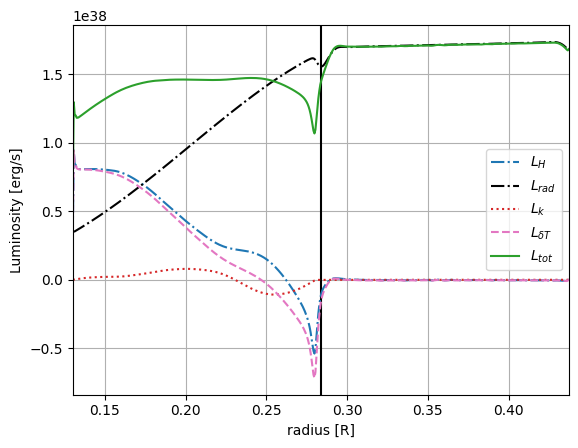

In [10]:
fig, ax = plt.subplots()
ax.axvline(r_env_init / r_tot, c="k")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_heat_instant"], c="tab:blue", ls="dashdot", label=r"$L_H$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_rad"], c="k", ls="dashdot", label=r"$L_{rad}$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_e_kin"], c="tab:red", ls="dotted", label=r"$L_k$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_enthalpy"], c="tab:pink", ls="dashed", label=r"$L_{\delta T}$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * (all_data["flux_heat_instant"] + all_data["flux_rad"] + all_data["flux_e_kin"]), c="tab:green", label=r"$L_{tot}$")
ax.grid()
ax.set_xlim(r_bot / r_tot, r_top / r_tot)
ax.set_xlabel("radius [R]")
ax.set_ylabel("Luminosity [erg/s]")
ax.legend()
plt.savefig(save_dir + "luminosities.png")

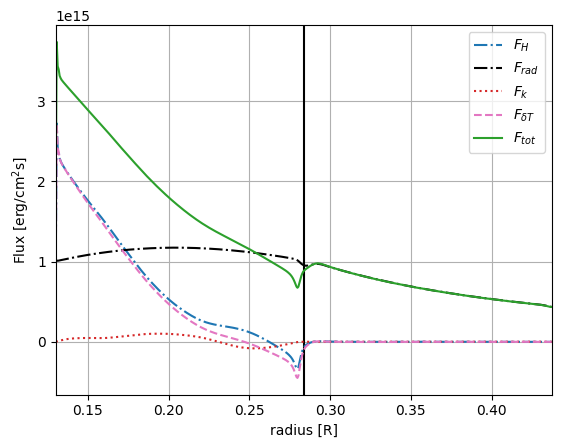

In [11]:
fig, ax = plt.subplots()
ax.axvline(r_env_init / r_tot, c="k")
ax.plot(all_data["radius"] / r_tot, all_data["flux_heat_instant"], c="tab:blue", ls="dashdot", label=r"$F_H$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_rad"], c="k", ls="dashdot", label=r"$F_{rad}$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_e_kin"], c="tab:red", ls="dotted", label=r"$F_k$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_enthalpy"], c="tab:pink", ls="dashed", label=r"$F_{\delta T}$")
ax.plot(all_data["radius"] / r_tot, (all_data["flux_heat_instant"] + all_data["flux_rad"] + all_data["flux_e_kin"]), c="tab:green", label=r"$F_{tot}$")
ax.grid()
ax.set_xlim(r_bot / r_tot, r_top / r_tot)
ax.set_xlabel("radius [R]")
ax.set_ylabel(r"Flux [erg/cm$^2$s]")
ax.legend()
plt.savefig(save_dir + "fluxes.png")